# Tree-Based Models - Decision Tree, Random Forest, Extra Trees and Gradient Boosting

Tree models answer a series of yes/no questions about the features ("does the comment contain `!`?", "is `oh great` present?") and route each comment down to a leaf that votes sarcastic / not sarcastic.

| Model | Idea |
|---|---|
| **Decision Tree** | One tree, grown on all training rows. Easy to read, but overfits easily. |
| **Random Forest** (bagging) | Many deep trees, each on a bootstrap sample and a random subset of features at every split. Votes are averaged. |
| **Extra Trees** (bagging) | Like a forest, but split thresholds are also drawn at random. Faster, often smoother. |
| **Gradient Boosting** (`HistGradientBoostingClassifier`) | Shallow trees added one at a time, each correcting the errors of the ones before. |

Their raw output is a **probability** of being sarcastic, so the default decision boundary is `prob >= 0.5` (the margin-based notebook used `score > 0`).

Pipeline (identical to `margin-based_baseline.ipynb`): load data → build features (TF-IDF, lexicon, surface) → compare feature sets → tune hyper-parameters on validation
→ retrain on the full train set → evaluate **once** on test → test on other datasets → save results.

## 1. Setup

import paths

In [1]:
from __future__ import annotations

import hashlib, json, re, sys, time, warnings
from collections import Counter
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import (accuracy_score, average_precision_score,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)

import scipy.sparse as sp

warnings.filterwarnings("ignore")

# Execution Parameters
QUICK = False
FORCE_RETRAIN = False
FINAL_FULL_TRAIN = not QUICK
SEED = 3244
N_JOBS = -1                      # cores used by the forests

# Location of Project Root Directory
from pathlib import Path
import sys

# Find project root
ROOT = Path.cwd().resolve()
while not (ROOT / "pipeline" / "load.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "pipeline" / "load.py").exists(), "Cannot find pipeline/load.py"
# Import functions from load.py
sys.path.insert(0, str(ROOT / "pipeline"))
from load import (
    load_split,
    load_lexicon,
    MODEL_SAFE_FEATURES,
    text_column,
    context_column
)

print("Project root:", ROOT)
print("Functions imported successfully!")
# Define Output Directories
RESULTS = ROOT / "results" / "tree-based"
FIGURES = ROOT / "figures" / "tree-based"
MODELS  = ROOT / "modelling" / "tree-based"
for d in (RESULTS, FIGURES, MODELS):
    d.mkdir(parents=True, exist_ok=True)
BASELINE_RESULTS = ROOT / "results" / "margin-based"      # read-only, used for the comparison table


# Constraints & Dataset Parameters
TRAIN_ROWS, VAL_ROWS = (20_000, 8_000) if QUICK else (200_000, 60_000)
TARGET_PRECISION = 0.75
DEFAULT_THR = 0.5                # probability cut-off for the "default" operating point
TRANSFER_TARGETS = ["figlang_reddit", "figlang_twitter",
                    "tweeteval_irony", "news_headlines"]

# Vocabulary limits for TfidfVectorizer.
# A tree considers columns one at a time, so 500k TF-IDF columns (margin-based notebook) would be far too slow.
# Keep only the most frequent terms.
MAX_TFIDF_FEATURES = 2_000
MIN_DF = 20

# Gradient boosting needs a dense matrix (rows x columns x 4 bytes).
# Cap the rows used for its FINAL fit so the dense matrix stays around 2.5 GB.
HGB_FINAL_ROWS = 300_000

# Forests with ~600k rows are several GB on disk; keep them out of the saved models unless asked.
SAVE_FOREST_MODELS = False

print(f"root      {ROOT}")
print(f"mode  {'QUICK' if QUICK else 'FULL'}   tuning train={TRAIN_ROWS:,} val={VAL_ROWS:,}   final on full train: {FINAL_FULL_TRAIN}")

Project root: C:\Users\ganra\Documents\cs3244_group1
Functions imported successfully!
root      C:\Users\ganra\Documents\cs3244_group1
mode  FULL   tuning train=200,000 val=60,000   final on full train: True


In [2]:
# Record library versions so results can be reproduced
import importlib.metadata as md_
VERSIONS = {p: md_.version(p) for p in
            ["scikit-learn", "pandas", "numpy", "joblib"]}
VERSIONS["python"] = sys.version.split()[0]
pd.Series(VERSIONS).to_frame("version")

,version
scikit-learn,1.9.0
pandas,3.0.5
numpy,2.5.2
joblib,1.5.3
python,3.14.6


## 2. Load Data

Uses `sarc_random` (balanced ~50/50), the **same train / validation / test split** as the margin-based baseline, so the numbers are directly comparable. To keep the many tuning runs fast, hyper-parameters are tuned on a **subsample**
(200k train / 60k validation). The **final** models are retrained on the full training set.

In [3]:
# Load data split
train_full, val_full, test = load_split("sarc_random")
rng = np.random.default_rng(SEED)

def subsample(df, n):
    return df if n >= len(df) else df.iloc[rng.choice(len(df), n, replace=False)].reset_index(drop=True)

# Subsample dataset for fast feature comparison and hyperparameter tuning
train = subsample(train_full, TRAIN_ROWS)
val   = subsample(val_full,   VAL_ROWS)

print(f"tuning : train {len(train):,}   val {len(val):,}")
print(f"full   : train {len(train_full):,}   val {len(val_full):,}   test {len(test):,}")
print(f"sarcastic rate - train {train.label.mean():.4f}   test {test.label.mean():.4f}")   # should be ~0.5
train[["label", "comment_clean", "parent_clean", "subreddit"]].head()

tuning : train 200,000   val 60,000
full   : train 641,738   val 137,516   test 137,515
sarcastic rate - train 0.5099   test 0.5088


,label,comment_clean,parent_clean,subreddit
0,0,This video is proof that you can be totally fu...,"But it's narrated in a British accent, it has ...",videos
1,1,Oh yeah that's not trivializing rape AT AAAAAL...,"He digs swigs, he fancies swoots, he has a pas...",SubredditDrama
2,1,"What's the problem, he left almost a whole met...","How to almost blow through a red light, in style",Roadcam
3,1,Beginning of the Seahawks Air Raid offense.,"If it's true, then now we have a monstrous 6'5...",nfl
4,0,What makes you say he's against war on drugs?,Trump is for the rights of states. This means ...,trees


## 3. Feature engineering

Same three blocks of clues as the margin-based notebook, so the two families are compared on equal information.

| Block | Size | What it captures |
|---|---|---|
| `tfidf` | up to 2,000 | Which of the most common words and 2-word phrases appear |
| `lex` | 16 | Emotion and sentiment of the reply, and how it clashes with the parent |
| `surf` | 22 | Writing style: exclamation marks, interjections, length, ... |

**What changes for trees**

- **No scaling.** A split such as `exclamation_count <= 2` only depends on the *order* of values, so `StandardScaler` is unnecessary. (`surface_block` still applies `log1p`, which keeps the order and keeps the features identical to the baseline.)
- **Much smaller TF-IDF vocabulary.** A tree scans columns to find the best split, so cost grows with the number of columns. The 2,000 most frequent terms (appearing in at least 20 comments) are kept instead of up to 500,000.
- Every block is still fitted on the **training set only** and applied unchanged to validation and test.

In [4]:
RE_TOKEN = re.compile(r"[a-z][a-z']+")          # identical to the glassbox / margin-based slot
def tokens(text: str) -> list[str]:
    return RE_TOKEN.findall(text.lower())

EMOTIONS = ["anger", "anticipation", "disgust", "fear", "joy",
            "sadness", "surprise", "trust", "positive", "negative"]
LEXICON_NAMES = ([f"nrc_{e}" for e in EMOTIONS] +
                 ["vader_mean", "vader_pos_share", "vader_neg_share",
                  "parent_vader_mean", "incongruity_pos_reply_neg_parent",
                  "incongruity_signed"])

VADER = load_lexicon("vader")
_nrc  = load_lexicon("nrc")
NRC   = {e: _nrc.get(e, set()) for e in EMOTIONS}

def _vader(tk):
    vals = [VADER[w] for w in tk if w in VADER]
    if not vals:
        return 0.0, 0.0, 0.0
    a = np.asarray(vals, dtype=np.float32)
    return float(a.mean()), float((a > 0).mean()), float((a < 0).mean())

def lexicon_block(text: pd.Series, parent: pd.Series) -> np.ndarray:
    out = np.zeros((len(text), len(LEXICON_NAMES)), dtype=np.float32)
    k = len(EMOTIONS)
    for r, (t, p) in enumerate(zip(text.fillna(""), parent.fillna(""))):
        tk = tokens(t); s = set(tk); n = max(1, len(tk))
        for j, e in enumerate(EMOTIONS):
            out[r, j] = len(s & NRC[e]) / n
        m, pos, neg = _vader(tk)
        pm, _, _ = _vader(tokens(p))
        out[r, k:k + 6] = [m, pos, neg, pm,
                           1.0 if (m > 0.05 and pm < -0.05) else 0.0, m * pm]
    return out

_warned = set()
def surface_block(df: pd.DataFrame) -> np.ndarray:
    '''The 22 model-safe numeric features. Columns a corpus lacks are filled with 0 (and reported once).'''
    missing = [c for c in MODEL_SAFE_FEATURES if c not in df.columns]
    if missing and tuple(missing) not in _warned:
        _warned.add(tuple(missing))
        print(f"  [surface] {len(missing)} columns absent in this corpus, filled with 0: {missing}")
    X = df.reindex(columns=MODEL_SAFE_FEATURES).astype(float).fillna(0.0).clip(lower=0.0)
    return np.log1p(X.to_numpy())

print(f"{len(LEXICON_NAMES)} lexicon features | VADER {len(VADER):,} tokens | {len(MODEL_SAFE_FEATURES)} surface features")

16 lexicon features | VADER 7,506 tokens | 22 surface features


In [5]:
class BlockBuilder:
    '''Fit the TF-IDF vocabulary on the train set; apply it unchanged to val/test sets. No scalers needed for trees.'''
    def __init__(self):
        self.tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=MIN_DF, sublinear_tf=True,
                                     max_features=MAX_TFIDF_FEATURES)

    def _text_and_context(self, df):
        txt = df[text_column(df)].fillna("")
        cc = context_column(df)
        ctx = df[cc].fillna("") if cc else pd.Series([""] * len(df), index=df.index)
        return txt, ctx

    def _blocks(self, df, fit):
        txt, ctx = self._text_and_context(df)
        lex, surf = lexicon_block(txt, ctx), surface_block(df)
        T = self.tfidf.fit_transform(txt) if fit else self.tfidf.transform(txt)
        return {"tfidf": T.astype(np.float32), "lex": sp.csr_matrix(lex),
                "surf": sp.csr_matrix(surf.astype(np.float32))}

    def fit_transform(self, df): return self._blocks(df, fit=True)
    def transform(self, df):     return self._blocks(df, fit=False)

FEATURE_SETS = {
    "tfidf only":            ["tfidf"],
    "tfidf + lexicon":       ["tfidf", "lex"],
    "lexicon only":          ["lex"],
    "tfidf + lexicon + surface": ["tfidf", "lex", "surf"],
}
def assemble(blocks: dict, names: list[str]):
    return sp.hstack([blocks[n] for n in names], format="csr", dtype=np.float32)

def feature_names(bb, names: list[str]) -> list[str]:
    parts = {"tfidf": list(bb.tfidf.get_feature_names_out()),
             "lex": list(LEXICON_NAMES), "surf": list(MODEL_SAFE_FEATURES)}
    return [f for n in names for f in parts[n]]

In [7]:
t0 = time.time()
bb = BlockBuilder()
B_train = bb.fit_transform(train)      # fit on TRAIN only
B_val   = bb.transform(val)            # validation only transformed, never fitted
y_train, y_val = train["label"].to_numpy(), val["label"].to_numpy()
print({k: v.shape for k, v in B_train.items()}, f"  ({time.time()-t0:.0f}s)")

# Preview vocabulary tokens generated by TF-IDF
names = bb.tfidf.get_feature_names_out()
pd.DataFrame(B_train["tfidf"][:5, :20].toarray(), columns=names[:20])

{'tfidf': (200000, 2000), 'lex': (200000, 16), 'surf': (200000, 22)}   (14s)


,000,10,100,11,12,15,16,20,24,25,30,40,50,60,90,99,ability,able,able to,about
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.12653
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000


## 4. Evaluation helpers

Exactly the same protocol as the margin-based baseline:

- Models are compared and ranked on the validation set using **ROC-AUC**, a threshold-free measure of overall classification performance.
- To ensure high confidence in sarcastic predictions, an operating decision threshold is fitted on validation predictions to achieve at least 75% precision while maximizing recall, and then applied unchanged to the test set.
- Standard metrics (accuracy, precision, recall, F1, ROC-AUC, PR-AUC, confusion matrix) are also logged at the default decision boundary (`P(sarcastic) >= 0.5`).

The only difference is the "score": tree models output `predict_proba(X)[:, 1]` (between 0 and 1) rather than a signed margin. Gradient boosting works on dense arrays, so `prep()` converts the sparse matrix for that model only.

In [14]:
def metrics(y, score, thr=DEFAULT_THR) -> dict:
    pred = (score >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "n": int(len(y)), "threshold": round(float(thr), 4),
        "accuracy":  round(float(accuracy_score(y, pred)), 4),
        "precision": round(float(precision_score(y, pred, zero_division=0)), 4),
        "recall":    round(float(recall_score(y, pred, zero_division=0)), 4),
        "f1":        round(float(f1_score(y, pred, zero_division=0)), 4),
        "roc_auc":   round(float(roc_auc_score(y, score)), 4),
        "pr_auc":    round(float(average_precision_score(y, score)), 4),
        "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    }

def pick_threshold(y, score, target_precision=TARGET_PRECISION) -> dict:
    '''Lowest score threshold on VALIDATION that reaches the target precision (= most recall).'''
    prec, rec, thr = precision_recall_curve(y, score)
    prec, rec = prec[:-1], rec[:-1]
    ok = np.where(prec >= target_precision)[0]
    if len(ok):
        i, rule = int(ok[np.argmax(rec[ok])]), f"precision >= {target_precision}"
    else:
        f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(prec), where=(prec + rec) > 0)
        i, rule = int(np.argmax(f1)), "max F1 (target precision unreachable)"
    return {"rule": rule, "threshold": float(thr[i]),
            "val_precision": round(float(prec[i]), 4), "val_recall": round(float(rec[i]), 4)}

MODEL_LABELS = {"dt": "Decision Tree", "rf": "Random Forest", "hgb": "Gradient Boosting"}

def make_model(kind: str, **p):
    if kind == "dt":
        return DecisionTreeClassifier(random_state=SEED, **{"min_samples_leaf": 5, **p})
    if kind == "rf":
        return RandomForestClassifier(random_state=SEED, n_jobs=N_JOBS,
                                      **{"n_estimators": 100, "min_samples_leaf": 2, "max_features": "sqrt", **p})
    if kind == "et":
        return ExtraTreesClassifier(random_state=SEED, n_jobs=N_JOBS,
                                    **{"n_estimators": 100, "min_samples_leaf": 2, "max_features": "sqrt", **p})
    return HistGradientBoostingClassifier(random_state=SEED, early_stopping=True, n_iter_no_change=15,
                                          **{"max_iter": 300, "learning_rate": 0.1, "max_leaf_nodes": 31, **p})

# Defaults used for the feature-set comparison (step 1). Forests use 100 trees here to keep the 16 fits quick.
DEFAULTS = {"dt": {"max_depth": 20, "min_samples_leaf": 5},
            "rf": {"n_estimators": 100, "min_samples_leaf": 2, "max_features": "sqrt"},
            "et": {"n_estimators": 100, "min_samples_leaf": 2, "max_features": "sqrt"},
            "hgb": {"learning_rate": 0.1, "max_leaf_nodes": 31}}

def prep(kind, X):
    '''Gradient boosting needs a dense array; the other trees accept sparse input.'''
    return X.astype(np.float32).toarray() if kind == "hgb" else X

def fit_score(kind, params, Xtr, ytr, Xva):
    m = make_model(kind, **params).fit(prep(kind, Xtr), ytr)
    return m, m.predict_proba(prep(kind, Xva))[:, 1]

## 5. Parameter Sweep — Step 1: Feature Set Comparison

In this step, all four tree models are evaluated on the validation set using default hyperparameters across four feature combinations:
- `tfidf only`: Represents the standard lexical baseline.
- `tfidf + lexicon`: Adds the 16 sentiment and emotion features.
- `lexicon only`: Measures the standalone impact of the 16 sentiment and emotion features.
- `tfidf + lexicon + surface`: Adds the 22 writing-style features.

Trees can use the small lexicon and surface blocks very effectively because each is a handful of strong, dense columns, which is where they usually beat linear models.

In [10]:
rows = []
for set_name, blocks in FEATURE_SETS.items():
    Xtr, Xva = assemble(B_train, blocks), assemble(B_val, blocks)
    for kind in MODEL_LABELS:
        t0 = time.time()
        _, s = fit_score(kind, DEFAULTS[kind], Xtr, y_train, Xva)
        rows.append({"feature_set": set_name, "model": kind, "n_features": Xtr.shape[1],
                     "val_auc": round(roc_auc_score(y_val, s), 4),
                     "val_acc": round(accuracy_score(y_val, (s >= DEFAULT_THR).astype(int)), 4),
                     "fit_s": round(time.time() - t0, 1)})
        print(rows[-1])

cmp_df = pd.DataFrame(rows).sort_values("val_auc", ascending=False).reset_index(drop=True)
BEST_SET = cmp_df.iloc[0]["feature_set"]
print(f"\nbest feature set on validation: {BEST_SET!r}")
cmp_df

{'feature_set': 'tfidf only', 'model': 'dt', 'n_features': 2000, 'val_auc': 0.6202, 'val_acc': 0.6036, 'fit_s': 6.0}
{'feature_set': 'tfidf only', 'model': 'rf', 'n_features': 2000, 'val_auc': 0.734, 'val_acc': 0.6724, 'fit_s': 124.5}
{'feature_set': 'tfidf only', 'model': 'et', 'n_features': 2000, 'val_auc': 0.7446, 'val_acc': 0.6806, 'fit_s': 178.8}
{'feature_set': 'tfidf only', 'model': 'hgb', 'n_features': 2000, 'val_auc': 0.7451, 'val_acc': 0.6774, 'fit_s': 217.9}
{'feature_set': 'tfidf + lexicon', 'model': 'dt', 'n_features': 2016, 'val_auc': 0.6297, 'val_acc': 0.5987, 'fit_s': 9.3}
{'feature_set': 'tfidf + lexicon', 'model': 'rf', 'n_features': 2016, 'val_auc': 0.73, 'val_acc': 0.6686, 'fit_s': 145.0}
{'feature_set': 'tfidf + lexicon', 'model': 'et', 'n_features': 2016, 'val_auc': 0.741, 'val_acc': 0.6772, 'fit_s': 185.7}
{'feature_set': 'tfidf + lexicon', 'model': 'hgb', 'n_features': 2016, 'val_auc': 0.747, 'val_acc': 0.681, 'fit_s': 212.3}
{'feature_set': 'lexicon only', 'mod

,feature_set,model,n_features,val_auc,val_acc,fit_s
0,tfidf + lexicon + surface,hgb,2038,0.7654,0.6963,217.1
1,tfidf + lexicon + surface,et,2038,0.7575,0.6894,220.0
2,tfidf + lexicon,hgb,2016,0.7470,0.6810,212.3
3,tfidf only,hgb,2000,0.7451,0.6774,217.9
4,tfidf only,et,2000,0.7446,0.6806,178.8
5,tfidf + lexicon + surface,rf,2038,0.7437,0.6790,155.7
6,tfidf + lexicon,et,2016,0.7410,0.6772,185.7
7,tfidf only,rf,2000,0.7340,0.6724,124.5
8,tfidf + lexicon,rf,2016,0.7300,0.6686,145.0
9,tfidf + lexicon + surface,dt,2038,0.6660,0.6318,24.4


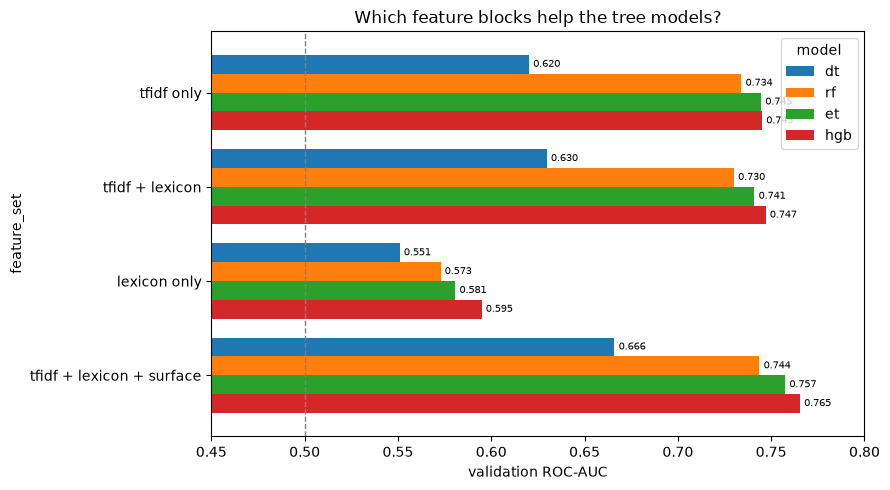

In [11]:
piv = cmp_df.pivot(index="feature_set", columns="model", values="val_auc").loc[list(FEATURE_SETS), list(MODEL_LABELS)]
ax = piv.plot.barh(figsize=(9, 5), width=0.8)
ax.axvline(0.5, ls="--", c="grey", lw=1); ax.set_xlim(0.45, max(0.8, piv.values.max() + 0.03))
ax.set_xlabel("validation ROC-AUC"); ax.set_title("Which feature blocks help the tree models?")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", padding=3, fontsize=7)
ax.invert_yaxis(); plt.tight_layout(); plt.savefig(FIGURES / "T01_feature_sets.png", dpi=150); plt.show()

## 6. Parameter sweep, step 2 - tune hyper-parameters

On the best feature set from step 5:

* **Decision Tree** - `max_depth` (how many questions deep; shallow = simple, deep = memorises) and `min_samples_leaf` (smallest group allowed at a leaf).
* **Random Forest** - `min_samples_leaf` and `max_features` (how many columns each split may look at; fewer = more diverse trees). 200 trees each.
* **Gradient Boosting** - `learning_rate` (step size of each new tree) and `max_leaf_nodes` (size of each tree). The number of trees is chosen automatically by early stopping.

All choices are made on the **validation** set by ROC-AUC. `max_features` floats mean a fraction of the columns, so keep them below 1.0.

In [15]:
DT_GRID  = [{"max_depth": d, "min_samples_leaf": l} for d in (10, 20, 40) for l in (5, 20, 50)]
RF_GRID  = [{"n_estimators": 200, "min_samples_leaf": l, "max_features": f}
            for l in (2, 5, 10) for f in ("sqrt", 0.05)]
HGB_GRID = [{"learning_rate": lr, "max_leaf_nodes": n} for lr in (0.05, 0.1) for n in (31, 63)]
GRIDS = {"dt": DT_GRID, "rf": RF_GRID, "hgb": HGB_GRID}

assert set(GRIDS) == set(MODEL_LABELS), "every model in MODEL_LABELS needs a grid (and vice versa)"
Xtr_best = assemble(B_train, FEATURE_SETS[BEST_SET])
Xva_best = assemble(B_val,   FEATURE_SETS[BEST_SET])

def tune(kind, grid):
    out = []
    for p in grid:
        t0 = time.time()
        m, s = fit_score(kind, p, Xtr_best, y_train, Xva_best)
        row = {**p, "val_auc": round(roc_auc_score(y_val, s), 4),
               "val_acc": round(accuracy_score(y_val, (s >= DEFAULT_THR).astype(int)), 4),
               "fit_s": round(time.time() - t0, 1)}
        if kind == "hgb":
            row["n_trees"] = int(m.n_iter_)
        out.append(row)
        print(kind, row)
    return pd.DataFrame(out).sort_values("val_auc", ascending=False).reset_index(drop=True)

INT_KEYS = {"n_estimators", "max_depth", "min_samples_leaf", "max_leaf_nodes", "max_iter"}
def best_params(df, keys):
    '''Top row of a trials table -> plain-Python parameter dict (NaN columns skipped, integer params cast back to int).'''
    row, out = df.iloc[0], {}
    for k in keys:
        if k in df.columns and not pd.isna(row[k]):
            v = row[k]
            out[k] = v if isinstance(v, str) else (int(v) if k in INT_KEYS else float(v))
    return out

TRIALS, BEST = {}, {}
for kind, grid in GRIDS.items():
    TRIALS[kind] = tune(kind, grid)
    TRIALS[kind].to_csv(RESULTS / f"{kind}_trials.csv", index=False)
    BEST[kind] = best_params(TRIALS[kind], list(grid[0].keys()))
    print(f"\nbest {MODEL_LABELS[kind]}: {BEST[kind]}   val AUC {TRIALS[kind].iloc[0]['val_auc']}\n")

dt {'max_depth': 10, 'min_samples_leaf': 5, 'val_auc': 0.666, 'val_acc': 0.6236, 'fit_s': 6.5}
dt {'max_depth': 10, 'min_samples_leaf': 20, 'val_auc': 0.6665, 'val_acc': 0.6232, 'fit_s': 11.4}
dt {'max_depth': 10, 'min_samples_leaf': 50, 'val_auc': 0.6674, 'val_acc': 0.6235, 'fit_s': 8.6}
dt {'max_depth': 20, 'min_samples_leaf': 5, 'val_auc': 0.666, 'val_acc': 0.6318, 'fit_s': 26.4}
dt {'max_depth': 20, 'min_samples_leaf': 20, 'val_auc': 0.6725, 'val_acc': 0.6306, 'fit_s': 36.6}
dt {'max_depth': 20, 'min_samples_leaf': 50, 'val_auc': 0.6796, 'val_acc': 0.6359, 'fit_s': 30.3}
dt {'max_depth': 40, 'min_samples_leaf': 5, 'val_auc': 0.6412, 'val_acc': 0.6148, 'fit_s': 87.4}
dt {'max_depth': 40, 'min_samples_leaf': 20, 'val_auc': 0.6649, 'val_acc': 0.6207, 'fit_s': 40.5}
dt {'max_depth': 40, 'min_samples_leaf': 50, 'val_auc': 0.6794, 'val_acc': 0.631, 'fit_s': 30.8}

best Decision Tree: {'max_depth': 20, 'min_samples_leaf': 50}   val AUC 0.6796

rf {'n_estimators': 200, 'min_samples_leaf': 

In [16]:
TRIALS["dt"]

,max_depth,min_samples_leaf,val_auc,val_acc,fit_s
0,20,50,0.6796,0.6359,30.3
1,40,50,0.6794,0.6310,30.8
2,20,20,0.6725,0.6306,36.6
3,10,50,0.6674,0.6235,8.6
4,10,20,0.6665,0.6232,11.4
5,10,5,0.6660,0.6236,6.5
6,20,5,0.6660,0.6318,26.4
7,40,20,0.6649,0.6207,40.5
8,40,5,0.6412,0.6148,87.4


In [17]:
TRIALS["rf"]

,n_estimators,min_samples_leaf,max_features,val_auc,val_acc,fit_s
0,200,2,sqrt,0.7454,0.6804,331.0
1,200,5,sqrt,0.7414,0.6778,172.1
2,200,2,0.05,0.7411,0.6774,712.3
3,200,5,0.05,0.7410,0.6761,420.6
4,200,10,sqrt,0.7367,0.6725,104.1
5,200,10,0.05,0.7365,0.6720,252.6


In [18]:
TRIALS["hgb"]

,learning_rate,max_leaf_nodes,val_auc,val_acc,fit_s,n_trees
0,0.10,63,0.7691,0.6981,302.7,300
1,0.05,63,0.7662,0.6964,366.0,300
2,0.10,31,0.7654,0.6963,219.8,300
3,0.05,31,0.7591,0.6911,270.1,300


## 7. Final models

Retrain each chosen configuration on the **full** `sarc_random/train` (when `FINAL_FULL_TRAIN` is on), refitting the TF-IDF vocabulary on that data.
The decision threshold is picked on the full validation set, then test is scored **once**.

Gradient boosting is fitted on at most `HGB_FINAL_ROWS` randomly chosen training rows, because it needs a dense matrix (see the setup cell). The other three models use every row.

In [19]:
t0 = time.time()
if FINAL_FULL_TRAIN:
    fit_df, thr_df = train_full, val_full
    bb_final = BlockBuilder()
    B_fit = bb_final.fit_transform(fit_df)
    B_thr = bb_final.transform(thr_df)
else:                                   # QUICK mode: reuse the tuning matrices
    fit_df, thr_df, bb_final, B_fit, B_thr = train, val, bb, B_train, B_val

B_test = bb_final.transform(test)
cols = FEATURE_SETS[BEST_SET]
X_fit, X_thr, X_test = (assemble(B, cols) for B in (B_fit, B_thr, B_test))
y_fit, y_thr, y_test = fit_df["label"].to_numpy(), thr_df["label"].to_numpy(), test["label"].to_numpy()
print(f"features ready: fit {X_fit.shape}  thr {X_thr.shape}  test {X_test.shape}  ({time.time()-t0:.0f}s)")

FINAL = {}      # name -> dict(model, thr, test metrics)
for kind, label in MODEL_LABELS.items():
    t0 = time.time()
    Xf, yf = X_fit, y_fit
    if kind == "hgb" and X_fit.shape[0] > HGB_FINAL_ROWS:
        idx = np.random.default_rng(SEED).choice(X_fit.shape[0], HGB_FINAL_ROWS, replace=False)
        Xf, yf = X_fit[idx], y_fit[idx]
    model = make_model(kind, **BEST[kind]).fit(prep(kind, Xf), yf)
    s_thr  = model.predict_proba(prep(kind, X_thr))[:, 1]
    s_test = model.predict_proba(prep(kind, X_test))[:, 1]
    thr = pick_threshold(y_thr, s_thr)
    FINAL[label] = {"model": model, "kind": kind, "params": BEST[kind], "fit_rows": int(Xf.shape[0]),
                    "threshold": thr, "test_score": s_test,
                    "test_default": metrics(y_test, s_test, DEFAULT_THR),
                    "test_at_precision_target": metrics(y_test, s_test, thr["threshold"]),
                    "fit_s": round(time.time() - t0, 1)}
    print(f"{label}: fitted on {Xf.shape[0]:,} rows in {FINAL[label]['fit_s']}s | threshold rule: {thr['rule']} -> {thr['threshold']:.4f}")

features ready: fit (641738, 2038)  thr (137516, 2038)  test (137515, 2038)  (56s)
Decision Tree: fitted on 641,738 rows in 95.7s | threshold rule: precision >= 0.75 -> 0.5529
Random Forest: fitted on 641,738 rows in 4482.5s | threshold rule: precision >= 0.75 -> 0.5305
Gradient Boosting: fitted on 300,000 rows in 444.4s | threshold rule: precision >= 0.75 -> 0.5266


## 8. Test results (sarc_random/test, scored once)

In [20]:
rows = []
for name, f in FINAL.items():
    for label, key in [(f"default (P >= {DEFAULT_THR})", "test_default"), (f"precision-target (val >= {TARGET_PRECISION})", "test_at_precision_target")]:
        m = f[key]
        rows.append({"model": name, "operating point": label, "threshold": m["threshold"],
                     "accuracy": m["accuracy"], "precision": m["precision"], "recall": m["recall"],
                     "f1": m["f1"], "roc_auc": m["roc_auc"], "pr_auc": m["pr_auc"]})
test_df = pd.DataFrame(rows)
display(test_df)

# sanity floor: accuracy of always guessing the majority class on this test set
majority_acc = round(float(max(y_test.mean(), 1 - y_test.mean())), 4)
print(f"majority-class baseline accuracy on test: {majority_acc}")

,model,operating point,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Decision Tree,default (P >= 0.5),0.5000,0.6430,0.7106,0.5034,0.5893,0.6894,0.7071
1,Decision Tree,precision-target (val >= 0.75),0.5529,0.6395,0.7504,0.4367,0.5521,0.6894,0.7071
2,Random Forest,default (P >= 0.5),0.5000,0.6913,0.7214,0.6408,0.6787,0.7603,0.7777
3,Random Forest,precision-target (val >= 0.75),0.5305,0.6893,0.7509,0.5825,0.6561,0.7603,0.7777
4,Gradient Boosting,default (P >= 0.5),0.5000,0.7037,0.7335,0.6558,0.6925,0.7759,0.7941
5,Gradient Boosting,precision-target (val >= 0.75),0.5266,0.7033,0.7527,0.6207,0.6804,0.7759,0.7941


majority-class baseline accuracy on test: 0.5088


In [21]:
# Side by side with the margin-based baseline (only if that notebook has been run)
base_path = BASELINE_RESULTS / "test_leaderboard.csv"
if base_path.exists():
    base = pd.read_csv(base_path)
    base["family"] = "margin-based"
    both = pd.concat([base, test_df.assign(family="tree-based")], ignore_index=True)
    both = both[both["operating point"].str.startswith("default")].sort_values("roc_auc", ascending=False)
    display(both[["family", "model", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]].reset_index(drop=True))
else:
    print(f"no baseline found at {base_path}; skipping comparison")

no baseline found at C:\Users\ganra\Documents\cs3244_group1\results\margin-based\test_leaderboard.csv; skipping comparison


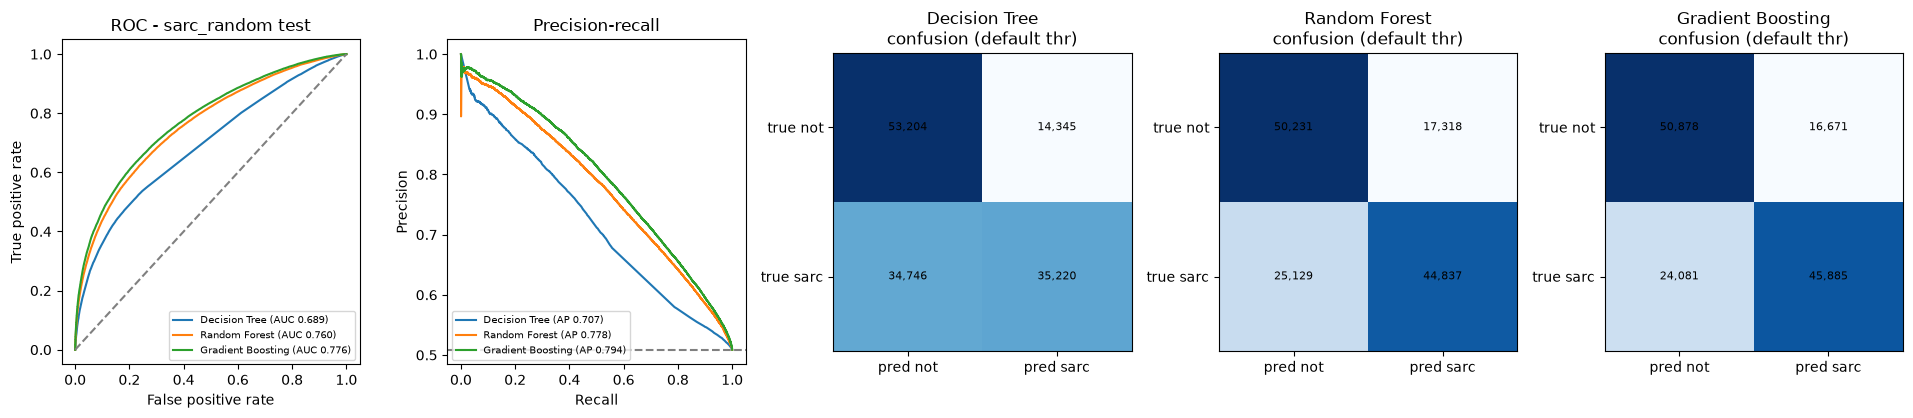

In [22]:
names_ = list(FINAL)
fig, axes = plt.subplots(1, 2 + len(names_), figsize=(5 * (2 + len(names_)) / 1.3, 4.2))
a1, a2, cm_axes = axes[0], axes[1], axes[2:]
for name, f in FINAL.items():
    fpr, tpr, _ = roc_curve(y_test, f["test_score"]); a1.plot(fpr, tpr, label=f"{name} (AUC {f['test_default']['roc_auc']:.3f})")
    p, r, _ = precision_recall_curve(y_test, f["test_score"]); a2.plot(r, p, label=f"{name} (AP {f['test_default']['pr_auc']:.3f})")
a1.plot([0, 1], [0, 1], "--", c="grey"); a1.set(title="ROC - sarc_random test", xlabel="False positive rate", ylabel="True positive rate"); a1.legend(loc="lower right", fontsize=7)
a2.axhline(y_test.mean(), ls="--", c="grey"); a2.set(title="Precision-recall", xlabel="Recall", ylabel="Precision"); a2.legend(loc="lower left", fontsize=7)
for ax, (name, f) in zip(cm_axes, FINAL.items()):
    c = f["test_default"]["confusion"]
    cm = np.array([[c["tn"], c["fp"]], [c["fn"], c["tp"]]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="black", fontsize=8)
    ax.set(title=f"{name}\nconfusion (default thr)", xticks=[0, 1], yticks=[0, 1],
           xticklabels=["pred not", "pred sarc"], yticklabels=["true not", "true sarc"])
plt.tight_layout(); plt.savefig(FIGURES / "T02_test_curves.png", dpi=150); plt.show()

## 9. What do the trees rely on?

Impurity-based feature importance for the single tree and the two forests (share of the total error reduction each column is responsible for; sums to 1). Gradient boosting in scikit-learn does not expose this directly, so it is left out.

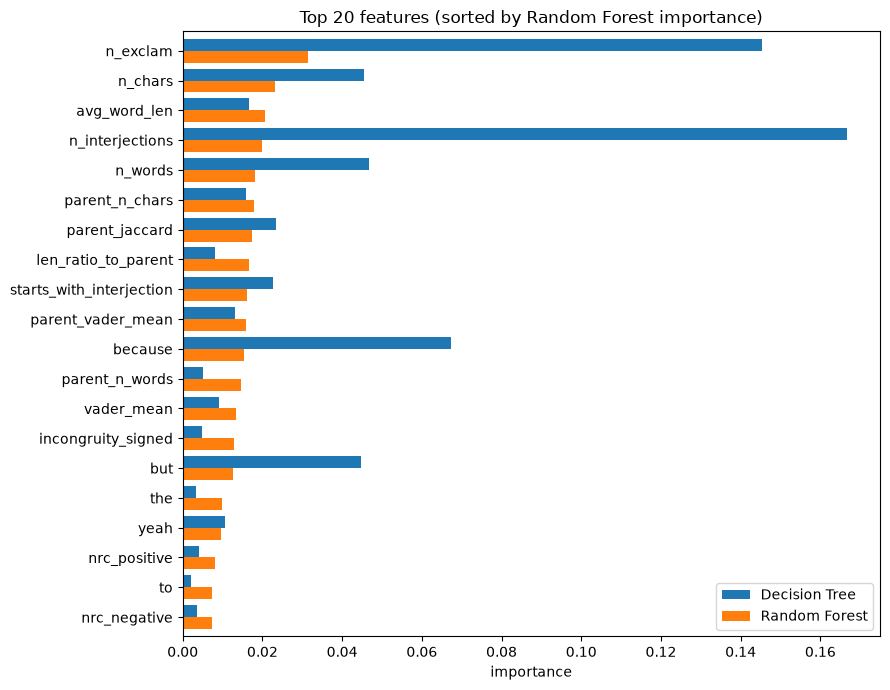

,Decision Tree,Random Forest
lex,0.053,0.109
surf,0.511,0.215
tfidf,0.437,0.676


In [23]:
fnames = feature_names(bb_final, cols)
imp = {}
for name, f in FINAL.items():
    if hasattr(f["model"], "feature_importances_"):
        imp[name] = pd.Series(f["model"].feature_importances_, index=fnames)
imp_df = pd.DataFrame(imp).sort_values(list(imp)[1] if len(imp) > 1 else list(imp)[0], ascending=False)
imp_df.to_csv(RESULTS / "tree_feature_importance.csv")

top = imp_df.head(20)
ax = top.plot.barh(figsize=(9, 7), width=0.8)
ax.invert_yaxis(); ax.set_xlabel("importance"); ax.set_title("Top 20 features (sorted by Random Forest importance)")
plt.tight_layout(); plt.savefig(FIGURES / "T03_feature_importance.png", dpi=150); plt.show()

# Which block does the model lean on?
block_of = {f: b for b in cols for f in feature_names(bb_final, [b])}
display(imp_df.groupby(imp_df.index.map(block_of)).sum().round(3))

## 10. Testing on other datasets

The models trained on SARC are applied, unchanged, to the **test split** of four other datasets. Nothing is refitted and nothing is selected on these scores.

| Dataset (name in code) | What it is | Tests whether the model... |
|---|---|---|
| `tweeteval_irony` | TweetEval Irony (SemEval-2018 Task 3): tweets with human-checked labels | transfers from Reddit to Twitter |
| `figlang_reddit` | FigLang 2020 shared task, Reddit part: replies with their earlier conversation turns | works on other Reddit data that has a longer context |
| `figlang_twitter` | FigLang 2020 shared task, Twitter part: same format, from Twitter | works on Twitter conversations |
| `news_headlines` | News Headlines Dataset: The Onion (sarcastic) vs HuffPost (not sarcastic) | works on clean, edited writing instead of informal comments |

Columns that a dataset lacks (e.g. a headline has no parent comment) are filled with 0 by the feature builder.

In [ ]:
transfer_rows = []
for tgt in TRANSFER_TARGETS:
    try:
        df = load_split(tgt, "test")
    except Exception as e:
        print(f"skip {tgt}: {e}"); continue
    X = assemble(bb_final.transform(df), cols); y = df["label"].to_numpy()
    for name, f in FINAL.items():
        s = f["model"].predict_proba(prep(f["kind"], X))[:, 1]
        m = metrics(y, s, DEFAULT_THR)
        transfer_rows.append({"target": tgt, "model": name, "n": m["n"], "positive_rate": round(float(y.mean()), 3),
                              "roc_auc": m["roc_auc"], "accuracy": m["accuracy"], "f1": m["f1"]})
transfer_df = pd.DataFrame(transfer_rows)
display(transfer_df)

if len(transfer_df):
    piv = transfer_df.pivot(index="target", columns="model", values="roc_auc")
    ax = piv.plot.bar(figsize=(9, 4), width=0.8); ax.axhline(0.5, c="black", ls="--", lw=1)
    ax.set_ylabel("ROC-AUC"); ax.set_title("Transfer off SARC (below dashed line = worse than chance)")
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7, padding=2)
    plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.savefig(FIGURES / "T04_transfer.png", dpi=150); plt.show()

## 11. Save results

Outputs saved to: `results/tree-based/`, `figures/tree-based/`, and `modelling/tree-based/`.
Random forests and extra trees fitted on the full training set are several GB each, so they are only written when `SAVE_FOREST_MODELS = True`.

In [24]:
if "VERSIONS" not in globals():
    VERSIONS = {}
if "transfer_df" not in globals():
    transfer_df = pd.DataFrame()

# Save CSV summaries
cmp_df.to_csv(RESULTS / "feature_set_comparison.csv", index=False)
test_df.to_csv(RESULTS / "test_leaderboard.csv", index=False)
if len(transfer_df):
    transfer_df.to_csv(RESULTS / "transfer.csv", index=False)

summary = {
    "task": "sarcasm detection, sarc_random",
    "seed": SEED,
    "quick_mode": QUICK,
    "versions": VERSIONS,
    "tuning_rows": {"train": int(len(train)), "val": int(len(val))},
    "final_fit_rows": int(len(fit_df)),
    "tfidf": {"max_features": MAX_TFIDF_FEATURES, "min_df": MIN_DF},
    "best_feature_set": BEST_SET,
    "feature_set_comparison": cmp_df.to_dict("records"),
    "models": {name: {"params": {k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in f["params"].items()},
                      "fit_rows": f["fit_rows"],
                      "threshold_rule": f["threshold"],
                      "test_default": f["test_default"],
                      "test_at_precision_target": f["test_at_precision_target"]}
               for name, f in FINAL.items()},
    "transfer": transfer_df.to_dict("records") if len(transfer_df) else [],
}

# Write summary JSON to disk
(RESULTS / "evaluation.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")

# Dump vectorizer and final models
joblib.dump({"tfidf": bb_final.tfidf, "feature_blocks": cols}, MODELS / "feature_pipeline.joblib")

for name, f in FINAL.items():
    if f["kind"] in ("rf") and not SAVE_FOREST_MODELS:
        continue
    joblib.dump(f["model"], MODELS / f"{f['kind']}.joblib", compress=3)

print("Saved successfully! Output directory contents:")
print("  " + "\n  ".join(sorted(p.name for p in RESULTS.iterdir())))

Saved successfully! Output directory contents:
  dt_trials.csv
  evaluation.json
  feature_set_comparison.csv
  hgb_trials.csv
  rf_trials.csv
  test_leaderboard.csv
  tree_feature_importance.csv
